# hst_corpus_70m Cell Graph

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 21.02.2025
- Date of Last Modification: 24.02.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [3]:
import logging
import os
import pickle
import random
from datetime import datetime

import anndata as ad
import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
import seaborn as sns
import squidpy as sq
from datasets import load_from_disk
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import train_test_split

from nichejepa.datasets import prepare_dataset
from nichejepa.infer import infer
from nichejepa.train import train
from nichejepa.utils.config import create_params_from_YAML_wandb_config
from nichejepa.utils.distributed import init_distributed
from nichejepa.utils.evaluation import clustering_metrics, classification_metrics

from analysis_utils import *

## 1.2 Load Config/Params
All setup will be done in the config file. Please edit that file to continue.

In [4]:
# Set params
dataset = 'hst_corpus_70m'
tokenizer = 'cell_graph'
load_timestamp = '19022025_023508_679' # counts
# load_timestamp = '20022025_082432_404' # rank
read_checkpoint = 'nichejepa-ep3.pth.tar'
niche_key = 'niche_type'

In [5]:
model_config_folder_path = '../../config/model'
artifacts_folder_path = '../../artifacts'
datasets_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

In [6]:
# Set up logger
rank=0
logging.basicConfig()
logger = logging.getLogger()
logger.setLevel(logging.INFO if rank == 0 else logging.ERROR)

In [7]:
# Load config
if not load_timestamp:
    params = create_params_from_YAML_wandb_config(f'{model_config_folder_path}/{dataset}_{tokenizer}.yaml',logger)
else:
    params = create_params_from_YAML_wandb_config(f'{artifacts_folder_path}/{dataset}/{load_timestamp}/params.yaml',logger)

if read_checkpoint:
    params['state']['read_checkpoint'] = read_checkpoint
if load_timestamp:
    params['state']['load_checkpoint'] = True

params

INFO:root:Loaded parameters from YAML file.


{'data': {'batch_size': 256,
  'dataset_name': 'hst_corpus_70m',
  'n_segments': 7,
  'num_workers': 24,
  'pin_memory': True,
  'precomputed_n_nonzero_tokens': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_6_n_nonzero_tokens_train.pkl',
  'precomputed_split': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/hst_corpus_70m_32_None_None_None_None_None_shifted_log_knn_6_precomputed_split_train.pkl',
  'val_batch_ids': 'None',
  'random_state': 0,
  'raw_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m',
  'sample_subset': False,
  'sampling_strategy': None,
  'seq_len_cell': 64,
  'seq_len_neighborhood': 384,
  'split': 0,
  'stratify': False,
  'token_dict_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl',
  'tokenized_data_folder_path': '/lustre/scratch126/cellgen/team361/DATASETS/gold/cell-graph-tokenizer/hst_corpus_70m/hs

In [8]:
# Define folder path for saving and loading artifacts
if not load_timestamp:
    current_timestamp = (
        datetime.now().strftime("%d%m%Y_%H%M%S") +
        f"_{datetime.now().microsecond // 1000:03d}")
    folder_path = os.path.join(artifacts_folder_path,
                               params['data']['dataset_name'],
                               current_timestamp)
else:
    folder_path = f'{artifacts_folder_path}/{dataset}/{load_timestamp}'
    
folder_path

'../../artifacts/hst_corpus_70m/19022025_023508_679'

# 2. Analysis

In [9]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'

## 2.1 Full Corpus

In [10]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

In [11]:
# Load dataset
dataset = load_from_disk(params['data']['tokenized_data_folder_path'])

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [12]:
# Set inference params
layer = params['meta']['enc_depth']
exclude_unshared_tokens = False # True, False
agg_type = 'avg' # 'avg', 'weighted_avg', 'cls'
latent_leiden_resolution = 0.5 # 0.1, 0.5
latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'

In [13]:
# Subset dataset
step_size = 2000000
steps = int(np.ceil(len(dataset)/step_size))

dataset_subsets = []

for i in range(steps):
    if ((i+1)*step_size) > len(dataset):
        end_step = len(dataset)
    else:
        end_step = (i+1)*step_size
    dataset_subsets.append(dataset.select(np.arange(i*step_size, end_step)))

In [21]:
dataset_subset = dataset_subsets[1]

In [22]:
batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))

# Get dataset IDs
dataset_ids = [batch.split('_')[1] for batch in batches]

In [ ]:
# Get batches for current dataset subset
for i, dataset_subset in enumerate(dataset_subsets):
    if i == 0:
        continue
    print(f'Iteration: {i}')
    
    # Get batches
    batches = list(set([token_dict_reverse[batch_value[0]] for batch_value in dataset_subset['batch_value_token']]))
    print(f'Batches: {batches}')
    
    # Get dataset IDs
    dataset_ids = list(set([batch.split('_')[1] for batch in batches]))
    print(f'Dataset IDs: {dataset_ids}')

    # Run model inference
    adata = infer(params,
                  dataset_subset,
                  load_folder_path=folder_path,
                  dataset_ids=dataset_ids,
                  obs_cols=None,
                  agg_type=agg_type,
                  masked_tokens=None,
                  agg_excluded_tokens=None,
                  cell_gene_ids=[],
                  neighborhood_gene_ids=[]
                 )
    
    # Save adata
    adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{step_size}_{i}.h5ad')

Iteration: 1
Batches: ['spv_24_batch1', 'spv_26_batch1', 'spv_25_batch1', 'spv_25_batch0', 'spv_26_batch0']
Dataset IDs: ['25', '24', '26']


INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(113, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:298: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
1607it [1:04:16,  2.42s/it]

## 2.2 Benchmarking Test Sets

### 2.2.1 chl59-8b_1p (NanoString CosMx Human NSCLC)

In [18]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '59_batch0',
    '59_batch3',
    '59_batch6',
    '59_batch7',
    '59_batch2',
    '59_batch4',
    '59_batch1',
    '59_batch5']
params['data']['val_batch_ids'] = None

In [19]:
# Set dataset params
dataset_name = 'chl59-8b_1p'
niche_key = 'niche'
batch_key = 'batch'

In [ ]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [ ]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

In [ ]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

In [ ]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

In [ ]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
`spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

### 2.2.2 chr78-11b_1p (ISS Cartana Human Reproductive Tract)

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '78_batch3',
    '78_batch10',
    '78_batch1',
    '78_batch0',
    '78_batch2',
    '78_batch6',
    '78_batch7',
    '78_batch9',
    '78_batch8',
    '78_batch4',
    '78_batch5']
params['data']['val_batch_ids'] = None

In [ ]:
# Set dataset params
niche_key = 'broad_anatomy'
batch_key = 'batch'
spot_sizes = [240 * 0.093] * len(batches)

### 2.2.3 xhs49-1b_1p (Xenium Human Melanoma)

In [ ]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '49_batch0']
params['data']['val_batch_ids'] = None

In [ ]:
# Set dataset params
niche_key = 'niche_name'
spot_size = 20

### 2.2.4 xhs1000-39b_1p (Xenium Human Skin - Eczema)

In [10]:
# Set test batch IDs
params['data']['precomputed_split'] = False
params['data']['test_batch_ids'] = [
    '1000_batch11',
    '1000_batch19',
    '1000_batch32']
params['data']['val_batch_ids'] = None

In [12]:
# Set dataset params
dataset_name = 'xhs1000-39b_1p'
niche_key = 'niche_type'
batch_key = 'sample'

In [13]:
# Load data
_, _, test_dataset = prepare_dataset(params)
test_dataset

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

Dataset({
    features: ['cell_degrees', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value_token', 'gene_panel_value_token', 'assay_value_token', 'species_value_token', 'tissue_value_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens', 'cls_tokens'],
    num_rows: 53655
})

In [14]:
# Run model inference
adata = infer(params,
              test_dataset,
              load_folder_path=folder_path,
              dataset_ids=list(set([batch_id.split('_')[0] for batch_id in params['data']['test_batch_ids']])),
              obs_cols=[niche_key],
              agg_type='avg',
              masked_tokens=None,
              agg_excluded_tokens=None,
              cell_gene_ids=[],
              neighborhood_gene_ids=[]
             )

# Save adata
adata.write(f'{folder_path}/adata_{read_checkpoint.split("-")[1].split(".")[0]}_{dataset_name}.h5ad')

INFO:root:GeneTransformerCountEncoder(
  (token_embed): Embedding(23407, 1024, padding_idx=0)
  (seg_embed): Embedding(113, 1024, padding_idx=0)
  (blocks): ModuleList(
    (0-5): 6 x Block(
      (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1024, out_features=3072, bias=True)
        (attn_drop): Dropout(p=0.0, inplace=False)
        (proj): Linear(in_features=1024, out_features=1024, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (drop_path): Identity()
      (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
      (mlp): MLP(
        (fc1): Linear(in_features=1024, out_features=4096, bias=True)
        (act): GELU(approximate='none')
        (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        (drop): Dropout(p=0.0, inplace=False)
      )
    )
  )
  (norm): LayerNorm((1024,), eps=1e-06, elementwise_affine=True)
  (value_embed): Embedding(100, 1024

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'loss', 'batch_size', 'world_size', 'lr']


0it [00:00, ?it/s]/lustre/scratch126/cellgen/team361/sb75/nichejepa/src/nichejepa/infer.py:298: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16,
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
210it [09:10,  2.62s/it]
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Loading metadata AnnDatas...
Loading AnnData objects from /lustre/scratch126/cellgen/team361/DATASETS/silver/hst_corpus_70m/xhs1000-39b_1p.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_un

In [15]:
# Extract batch from cell ID
adata.obs["batch"] = [cell_id.split('_')[1].replace('batch', '') for cell_id in adata.obs.index.tolist()]

In [16]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')

Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 11
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 10
Number of latent clusters 11
Number of latent clusters 10
Number of latent clusters 12
NMI is 0.5756409465876471. ARI is 0.37179148790015437.


/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
... storing 'batch' as categorical
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax =

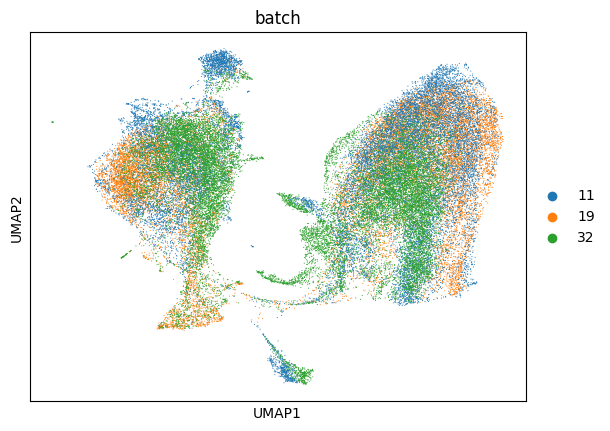

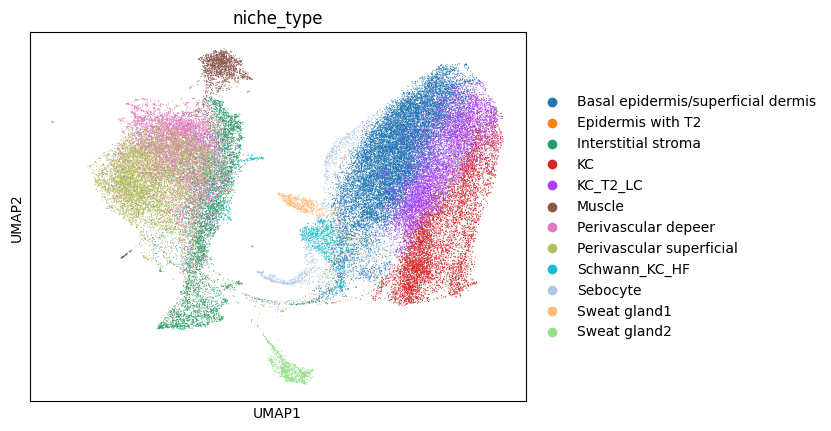

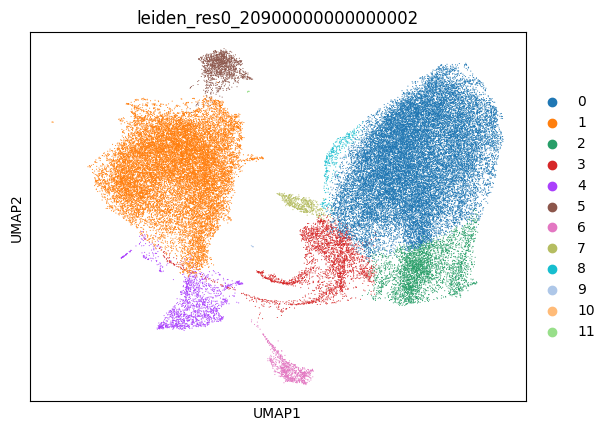

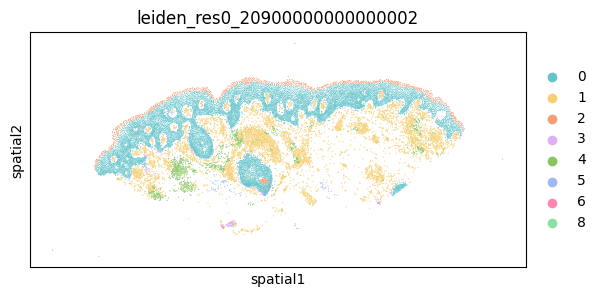

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


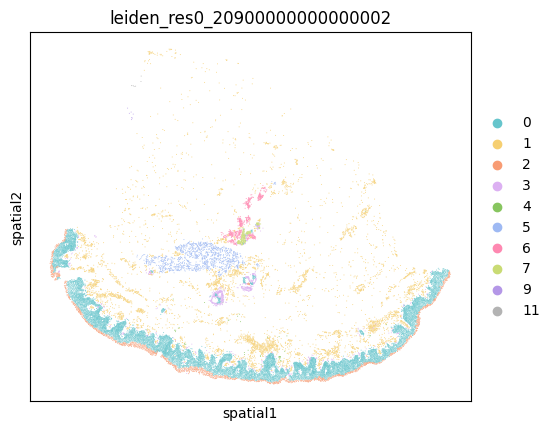

/lustre/scratch126/cellgen/team361/sb75/conda/envs/nichejepa_new/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


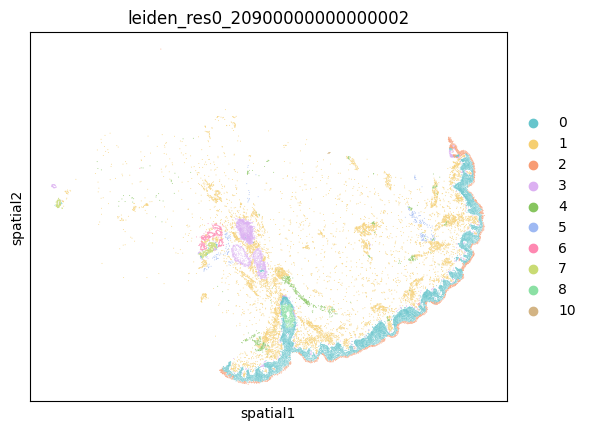

In [17]:
# Perform clustering until number of ground truth niches is matched
latent_leiden_resolution = 0.2
i = 0
n_niches = adata.obs[niche_key].nunique()
while (i<25):
    latent_cluster_key = f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}'
    i += 1
    sc.tl.leiden(adata,
                 neighbors_key='neighborhood',
                 key_added=latent_cluster_key,
                 resolution=latent_leiden_resolution)

    n_latent_clusters = adata.obs[latent_cluster_key].nunique()
    print(f"Number of latent clusters {n_latent_clusters}")
    if n_latent_clusters == n_niches:
        break
    elif n_latent_clusters < (n_niches - 5):
        latent_leiden_resolution += 0.02
    elif n_latent_clusters < (n_niches - 3):
        latent_leiden_resolution += 0.01
    elif n_latent_clusters < n_niches:
        latent_leiden_resolution += 0.001
    elif n_latent_clusters > (n_niches + 5):
        latent_leiden_resolution -= 0.02
    elif n_latent_clusters > (n_niches + 3):
        latent_leiden_resolution -= 0.01
    else:
        latent_leiden_resolution -= 0.001

# Compute metrics
adata = adata[~adata.obs[niche_key].isna()] # Remove missing ground truth
labels = adata.obs[niche_key]
labels_pred = adata.obs[latent_cluster_key]
nmi = normalized_mutual_info_score(labels, labels_pred, average_method="arithmetic")
ari = adjusted_rand_score(labels, labels_pred)
print(f'NMI is {nmi}. ARI is {ari}.')

# Plot UMAPs
os.makedirs(f'{folder_path}/figures', exist_ok=True)
labels = ['batch', niche_key, latent_cluster_key]
# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

# Plot niches in tissue
spot_sizes = [10] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])

In [ ]:
# Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'neighborhood_emb_layer_{layer}',
                key_added='neighborhood')
sc.tl.umap(adata,
           neighbors_key='neighborhood')
sc.tl.leiden(adata,
             neighbors_key='neighborhood',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

In [ ]:
labels = ['batch', 'niche_type', 'cell_type', latent_cluster_key]

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

In [ ]:
spot_sizes = [20] * len(adata.obs['batch'].unique().tolist())
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])
    #sq.pl.spatial_scatter(adata_batch,
    #                      color=latent_cluster_key,
    #                      shape=None)

In [ ]:
## Compute UMAP representation for (aggregated) neighborhood gene embeddings
sc.pp.neighbors(adata,
                n_neighbors=15,
                use_rep=f'cell_emb_layer_{layer}',
                key_added='cell')
sc.tl.umap(adata,
           neighbors_key='cell')
sc.tl.leiden(adata,
             neighbors_key='cell',
             key_added=latent_cluster_key,
             resolution=latent_leiden_resolution)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch', 'niche_type', 'cell_type', latent_cluster_key]

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

In [ ]:
spot_sizes = [300, 50]
batch_ids = adata.obs['batch'].unique().tolist()
for i, batch_id in enumerate(batch_ids):
    adata_batch = adata[adata.obs['batch'] == batch_id]
    sc.pl.spatial(adata_batch,
                  color=latent_cluster_key,
                  palette=custom_palette,
                  spot_size=spot_sizes[i])
    #sq.pl.spatial_scatter(adata_batch,
    #                      color=latent_cluster_key,
    #                      shape=None)

In [ ]:
sq.gr.spatial_neighbors(adata,
                        coord_type='generic',
                        spatial_key='spatial',
                        delaunay=True,
                        set_diag=False,
                        )

adata.obs['n_neighbors'] = adata.obsp['spatial_connectivities'].toarray().sum(1)

labels = ['n_neighbors'] # ['major_brain_region', 'Main_molecular_tissue_region']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_{agg_type}'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

In [ ]:
adata.obs['n_neighbors'].value_counts()

In [ ]:
adata_batch = adata[adata.obs['batch'] == 'batch1']

In [ ]:
sq.pl.spatial_scatter(adata_batch,
                      color=f'leiden_res{str(latent_leiden_resolution).replace(".", "_")}',
                      shape=None)

In [ ]:
adata_test = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_labels/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad')

In [ ]:
np.min(adata_batch.obsm['spatial'])

In [ ]:
adata_batch.shape

In [ ]:
adata_test.shape

In [ ]:
np.min(adata_test.obsm['spatial'])

In [ ]:
adata_test.obsm['spatial']

In [ ]:
sq.pl.spatial_scatter(adata_test,
                      color='Main_molecular_tissue_region',
                      shape=None)

## 3.3 Plot Embedding Similarity Stats

In [ ]:
similarity_stats = compute_similarity_stats(
    adata,
    n_samples=None,
    type_key='niche_type',
    embedding_key=f'neighborhood_emb_layer_{layer}')
plot_similarity_heatmaps(similarity_stats)

## 3.4 Compute Metrics

In [ ]:
os.makedirs(f'{folder_path}/metrics', exist_ok=True)

labels = ['cell_types', 'major_brain_region']

# NMI & ARI for label cols (neighborhood embedding)
for label in labels:
    cell_type_metrics = clustering_metrics(
        adata,
        emb_key=f'neighborhood_emb_layer_{layer}',
        label_col=label)
    
    metrics_df = pd.DataFrame([cell_type_metrics])
    metrics_df.to_csv(f'{folder_path}/metrics/{label}_metrics{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.csv', index=False)

## 3.5 Plot Loss Curve

In [ ]:
df = pd.read_csv(f'{folder_path}/nichejepa_r0.csv')
df['loss'] = pd.to_numeric(df['loss'], errors='coerce')

plt.figure(figsize=(10, 6))
plt.plot(df.index,df['loss'])
plt.title('Loss Function Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [ ]:
adata_starmap = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/starmap_plus_mouse_cns_batch15.h5ad')
adata_merfish = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/mmb0-1b_smb1-1b_1p_label/merfish_mouse_brain_239-batch_batch82.h5ad')

# Check that genes are the same
(adata_starmap.var != adata_merfish.var).any()

# adata_starmap.X.toarray().sum(1)
# adata_merfish.X.toarray().sum(1)

np.mean(adata_merfish.X.sum(1))

np.mean(adata_starmap.X.sum(1))

adata_concat = adata_starmap.concatenate(adata_merfish)

adata_concat.X = adata_concat.X.toarray() / adata_concat.X.toarray().sum(axis=1).reshape(-1, 1) * 10_000
sc.pp.log1p(adata_concat)

adata_concat.X

adata.X.sum(1x).value_counts()

adata_concat.X[0, :].shape

# Get unique values and their counts
unique_values, counts = np.unique(adata_concat.X[1, :], return_counts=True)

# Print the results
for value, count in zip(unique_values, counts):
    print(f"Value {value} occurs {count} times")

plt.hist(adata_concat.X.toarray(), bins=50, edgecolor='black')

sc.pp.neighbors(adata_concat,
                n_neighbors=15,
                use_rep='X')
sc.tl.umap(adata_concat)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata_concat,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_pca'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

for i in range(len(test_dataset["gene_tokens"])):
    test_dataset["gene_tokens"][i]

top_k = 10

embedding_dict = {i: np.random.rand(768) for i in range(1672)}
averaged_embeddings = []

for tokens in test_dataset["gene_tokens"]:
    # Filter out the zero tokens
    valid_tokens = [token for token in tokens[:top_k] if token != 0]

    # Retrieve embeddings for the valid tokens
    if valid_tokens:
        embeddings = [embedding_dict[token] for token in valid_tokens]
        
        # Calculate the average embedding across the sequence
        avg_embedding = np.mean(embeddings, axis=0)
    else:
        # If no valid tokens, create a zero vector (or handle as desired)
        avg_embedding = np.zeros(768)
    
    # Append the averaged embedding for this observation
    averaged_embeddings.append(avg_embedding)

# Convert the list of averaged embeddings to a numpy array
averaged_embeddings = np.array(averaged_embeddings)

# Assuming adata is your AnnData object
# Store the averaged embeddings in adata.obsm
adata = ad.AnnData(X=averaged_embeddings)  # Initialize adata or use an existing one

adata.obs['batch'] = [element[0] for element in test_dataset['batch_token']]

sc.pp.neighbors(adata,
                n_neighbors=15)
sc.tl.umap(adata)

os.makedirs(f'{folder_path}/figures', exist_ok=True)

labels = ['batch']

# Plot (aggregated) neighborhood gene embeddings, colored by labels
for label in labels:
    sc.pl.umap(adata,
               color=label,
               show=False)
    plt.savefig(f'{folder_path}/figures/{label}_umap_random_embed'
                f'{"_shared_genes" if exclude_unshared_tokens and agg_type != "cls" else ("_all_genes" if agg_type != "cls" else "")}.svg',
                dpi=300,
                bbox_inches='tight')

sq.pl.spatial_scatter(adata_starmap,
                      color="major_brain_region",
                      shape=None)

sq.pl.spatial_scatter(adata_merfish,
                      color="major_brain_region",
                      shape=None) 

In [ ]:
import pickle

with open('/lustre/scratch126/cellgen/team361/DATASETS/tokenizer/cell-graph-tokenizer/human_cohort1_50m/token_dictionary.pkl', 'rb') as file:
    token_dict = pickle.load(file)

n_special_values = 0
for key, val in token_dict.items():
    if "spv" in key:
        n_special_values += 1

vocab_size = len(token_dict)

print(f"Number of tokens {vocab_size}.")
print(f"Number of special value tokens {n_special_values}.")

In [ ]:
    max_special_tokens = sum(1 for key in token_dict if "cls" in key) + sum(
        1 for key in token_dict if "spt" in key)

In [ ]:
max_special_tokens

In [ ]:
for key, val in token_dict.items():
    if "spv" in key:
        n_special_values += 1

In [ ]:
item = train_dataset[0]
item2 = train_dataset[1]

In [ ]:
len(train_dataset) # 53M human cells

In [ ]:
cell_ids = train_dataset['cell_id']

In [ ]:
len(cell_ids)

In [ ]:
len(set(cell_ids))

In [ ]:
adata_raw = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/bronze/xhs1000-39b_1p/adata_5k_xenium_skin.h5ad')

batch_mapping_dict = {value: idx for idx, value in enumerate(adata_raw.obs['info_id'].unique().tolist())}

batch_mapping_dict

In [ ]:
adata_annotated_batch = adata[adata.obs['batch'] == 'lung9_rep1']

In [ ]:
adata_annotated_batch.obs.columns

In [ ]:
adata_annotated_batch.obs

In [ ]:
adata_temp =  sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/chl59-8b_1p/Lung9_Rep2+SMI+Flat+data.tar.h5ad')

In [ ]:
adata_temp.obs.columns

In [ ]:
adata_temp.obs

In [ ]:
adata_temp.obs[['cell_id', 'Sanger patient ID', 'Timepoint']]

In [ ]:
cluster_key = 'NICHE_NAMES'
spot_size = 30

In [ ]:
sc.pl.spatial(adata_temp,
              color=cluster_key,
              spot_size=spot_size)

In [ ]:
adata = sc.read_h5ad('/lustre/scratch126/cellgen/team361/DATASETS/silver/chr78-11b_1p/CM019_annotated.h5ad')

In [ ]:
adata.obs.columns

In [ ]:
adata.obs

In [ ]:
cluster_key = 'broad_anatomy'
spot_size = 100

In [ ]:
sc.pl.spatial(adata,
              color=cluster_key,
              spot_size=spot_size)

In [ ]:
adata_raw.obs['broad_anatomy']

In [ ]:
adata_raw.obs['leiden_log1pnorm_res']

In [ ]:
adata_raw.obs['Sanger patient ID'].unique()

In [ ]:
adata_raw.obs

In [ ]:
{value: idx for idx, value in enumerate(adata_raw.obs['info_id'].unique().tolist())}